# Трещина из-за неодинаковой свободной усадки в необлучённой таблетке UO₂

**Базовый эксперимент.** Y. W. Rhee и соавт., *In-Situ Observation of Sintering Shrinkage of UO₂ Compacts Derived from Different Powder Routes*, KNS, 2015, § 2–3, рис. 3. Это та же работа, что использована в расчёте полостей. В ней определяли усадку прессовок разных порошковых маршрутов. Исходные габариты прессовки служат координатной рамкой демонстрации. [Исходная публикация](https://www.kns.org/files/pre_paper/34/15A-419%EC%9D%B4%EC%98%81%EC%9A%B0.pdf).

**Как пользоваться.** Исполните ячейки по порядку в Colab/Jupyter. Примеры со случайной выборкой проверяют поведение уравнений. Параметры рассеяния, число участков и нормировочная длина — настройки численного опыта. Для интерпретации в физических единицах задайте размеры своего образца и измеренные входы. Маркеры на обзорной 3D-картинке показывают центры.

## 1. Физическая постановка и источники

Два идеально связанных слоя с одинаковыми E и равными площадями хотят дать разные свободные осевые деформации. При свободном от внешней силы композите их общая деформация равна среднему, максимальное растяжение $\sigma=E|\epsilon_1^*-\epsilon_2^*|/2$. Это одноосная оценка без высокотемпературной релаксации. Принята затравка нормалью к оси растяжения. Для реального неоднородного спекания требуется вязкоупругий или вязкий расчёт напряжения. Для внутренней круглой затравочной трещины в бесконечном упругом теле $K_I=2\sigma_n\sqrt{a/\pi}$. При $K_I/K_{IC}\ge1$ возможно начало роста. Размеры в файле — размеры исходных затравок. Критерий не задаёт длину выросшей трещины или её раскрытие. Для сомкнутых берегов используется положительная часть нормального напряжения.

- [Some factors affecting densification and grain growth in the sintering of uranium dioxide](https://www.sciencedirect.com/science/article/pii/S0022311521001422)

- [Microwave process for sintering of uranium dioxide](https://www.sciencedirect.com/science/article/abs/pii/S002231150300521X)

- [K для круглой внутренней трещины, рис. 9.4–2b](https://materials.duke.edu/XCOURSES/ME83/X02_Mechanics.pdf)

- [Grain Boundary and Lattice Fracture Toughness of UO₂ Measured Using Small-Scale Mechanics](https://www.ornl.gov/publication/grain-boundary-and-lattice-fracture-toughness-uo2-measured-using-small-scale-mechanics)

## 2. Условия и параметры

**Для калибровки нужны:** Измеренные радиусы зародышей, ориентации, поле напряжений и трещиностойкость соответствующей стадии. Полезно разделить зародыши на границах зёрен и внутри зёрен, если есть EBSD и данные K_IC. Вблизи наружной поверхности требуется поправка на конечную геометрию.

CSV использует относительный исходный размер scale = размер / L0_UM; для поля плотности scale задаёт относительную неоднородность. Координаты могут быть измеренными. При отсутствии CSV выборка контрольная логнормальная, с единичным средним.

In [1]:
# Размеры исходной прессовки Rhee, в мм. Для спечённой замените фактически измеренными.
R_MM, H_MM = 5.15, 8.5
COUNTS = [25, 50, 100, 200]  # вложенные выборки расчётных точек или объектов
SEED = 42  # целое число для воспроизводимости; None даёт новую реализацию
L0_UM = 1.0   # единица длины демонстрационной геометрии, не измерение UO₂
CV = 0.2      # проверочный относительный разброс, не оценка по статье
INPUT_CSV = None  # путь к CSV со столбцом scale; необязательно x_mm,y_mm,z_mm
OUTPUT_ROOT = 'uo2_defect_results'

STRESS_SCALE = 2.0  # E*eps_ref*sqrt(L0)/K_IC
STRAIN_MISMATCH = 1.0  # разность собственных деформаций / eps_ref
LOAD = STRESS_SCALE*abs(STRAIN_MISMATCH)/2
NAME='12_shrinkage_crack'
ROLE='crack'
RESULT_LABEL='Коэффициент KⅠ/KⅠс'

## 3. Случайная выборка и воспроизводимость

Один seed задаёт связанные варианты N. Каждый меньший набор является началом большего. Таблица измерений заменяет генерацию исходных размеров.

In [2]:
from pathlib import Path
from datetime import datetime
import json, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
assert len(COUNTS)>0 and all(type(n) is int and n>0 for n in COUNTS)
assert min(R_MM,H_MM,L0_UM)>0 and np.isfinite([R_MM,H_MM,L0_UM,CV]).all() and CV>=0
N = max(COUNTS)
seed = int(np.random.SeedSequence().entropy) if SEED is None else SEED
rng, pos_rng = [np.random.default_rng(s) for s in np.random.SeedSequence(seed).spawn(2)]
out = Path(OUTPUT_ROOT)/NAME/datetime.now().strftime('run_%Y%m%d_%H%M%S_%f')
out.mkdir(parents=True)
params = {k:v for k,v in list(globals().items()) if k.isupper() and isinstance(v,(str,float,int,list,type(None)))}
params['effective_seed'] = seed
(out/'parameters.json').write_text(json.dumps(params,ensure_ascii=False,indent=2),encoding='utf8')
sample = None
if INPUT_CSV is None:
    sigma = np.sqrt(np.log1p(CV**2))
    scale = rng.lognormal(-sigma**2/2,sigma,N)
else:
    sample = pd.read_csv(INPUT_CSV).iloc[:N].copy()
    if len(sample)!=N: raise ValueError('В таблице меньше строк, чем max(COUNTS)')
    scale = sample['scale'].to_numpy(dtype=float)
assert np.all(np.isfinite(scale)) and np.all(scale>0)

def place(bounds,check_overlap):
    coords = []
    use_positions = sample is not None and all(c in sample for c in ['x_mm','y_mm','z_mm'])
    if sample is not None and any(c in sample for c in ['x_mm','y_mm','z_mm']) and not use_positions:
        raise ValueError('Укажите все три координаты или только scale')
    for i,b in enumerate(bounds):
        if b>=min(R_MM,H_MM/2): raise ValueError('Объект не помещается при заданном масштабе')
        for attempt in range(1 if use_positions else 10000):
            if use_positions:
                point = sample.iloc[i][['x_mm','y_mm','z_mm']].to_numpy(float)
            else:
                angle = pos_rng.uniform(0,2*np.pi)
                r = (R_MM-b)*np.sqrt(pos_rng.random())
                point = np.array([r*np.cos(angle),r*np.sin(angle),pos_rng.uniform(b,H_MM-b)])
            fits = np.hypot(*point[:2])+b <= R_MM and b <= point[2] <= H_MM-b
            if fits and (not check_overlap or all(np.linalg.norm(point-q)>b+bounds[j] for j,q in enumerate(coords))):
                break
        else: raise ValueError('Проверьте пересечения, координаты и единицы длины')
        coords.append(point)
    return np.asarray(coords)

def spheres(relative_radius):
    return L0_UM*np.repeat(np.asarray(relative_radius)[:,None],3,axis=1)

extra = {}

## 4. Расчёт локального состояния

Формулы раздела 1 применяются к каждому участку. Контрольные равенства проверяют баланс или допустимые пределы результата.

In [3]:
assert LOAD>=0
# Нормаль затравки совпадает с направлением заданного растяжения z.
extra.update(nx=np.zeros(N),ny=np.zeros(N),nz=np.ones(N))
stress_ratio = np.full(N,LOAD)
value = 2*stress_ratio*np.sqrt(scale/np.pi)
extra['eligible_for_growth'] = value>=1
axes = np.column_stack([scale,scale,np.zeros(N)])*L0_UM
assert np.all(value>=0)
xyz = place(axes.max(axis=1)/1000,True)

## 5. Результаты по вариантам

Исходные и итоговые параметры записываются построчно в CSV. Мин. и макс. относятся к данной выборке.

In [4]:
assert np.isfinite(value).all() and np.isfinite(axes).all() and np.all(axes>=0)
data = pd.DataFrame(dict(site=np.arange(1,N+1),scale=scale,x_mm=xyz[:,0],y_mm=xyz[:,1],
                         z_mm=xyz[:,2],result=value,**extra))
if ROLE!='field':
    data[['a_um','b_um','c_um']] = axes
    data['volume_um3'] = 4*np.pi/3*np.prod(axes,axis=1)
data.to_csv(out/'sites.csv',index=False)
summaries = []
for n in sorted(set(COUNTS)):
    g = data.iloc[:n]
    g.to_csv(out/f'sites_N{n}.csv',index=False)
    row = dict(N=n,mean=g.result.mean(),minimum=g.result.min(),median=g.result.median(),
               maximum=g.result.max(),sd=g.result.std(ddof=1) if n>1 else np.nan)
    if 'volume_um3' in g and ROLE!='crack': row['sum_volume_um3']=g.volume_um3.sum()
    if ROLE=='crack': row['growth_criterion_met']=int(g.eligible_for_growth.sum())
    summaries.append(row)
summary = pd.DataFrame(summaries)
summary.to_csv(out/'summary.csv',index=False)
display(summary.round(5))

N,mean,minimum,median,maximum,sd,growth_criterion_met
25,1.12041,0.91959,1.12780,1.34227,0.11207,21
50,1.12652,0.91959,1.12804,1.44595,0.10994,43
100,1.12939,0.91959,1.12610,1.44595,0.11237,86
200,1.12740,0.74505,1.12610,1.44595,0.10794,175


## 6. Пространственное распределение и разброс

Цвет показывает рассчитанную характеристику. Интервал на правом графике — наблюдаемый размах.

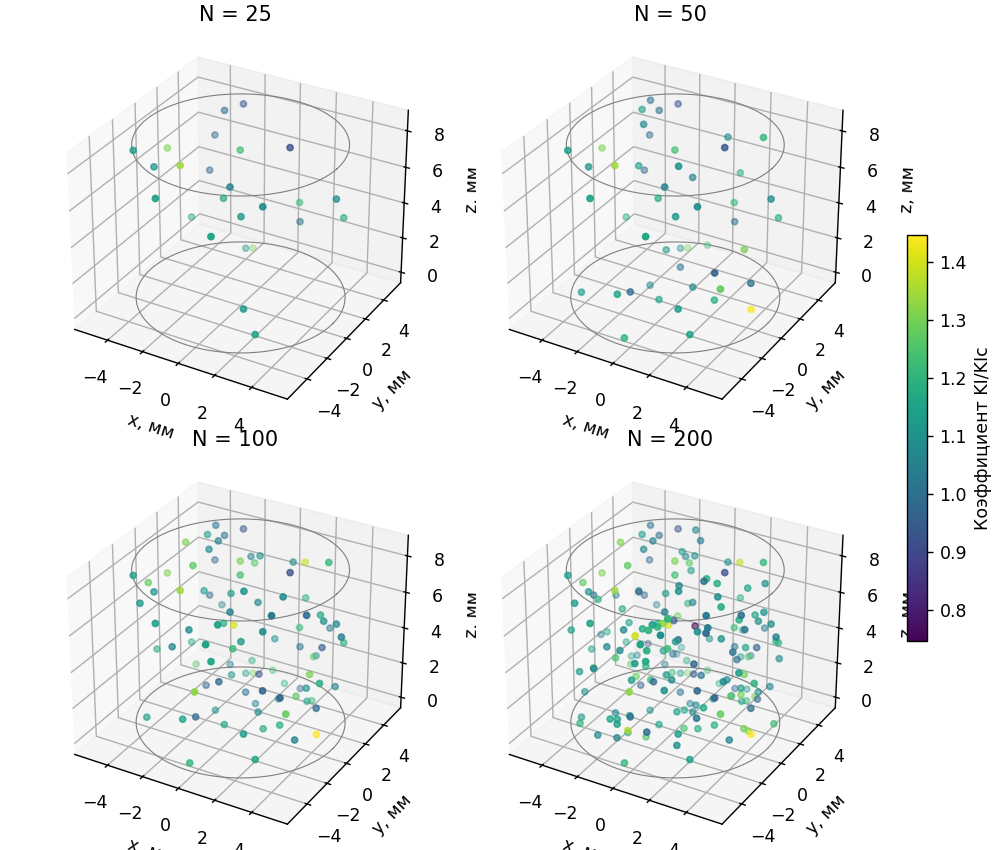

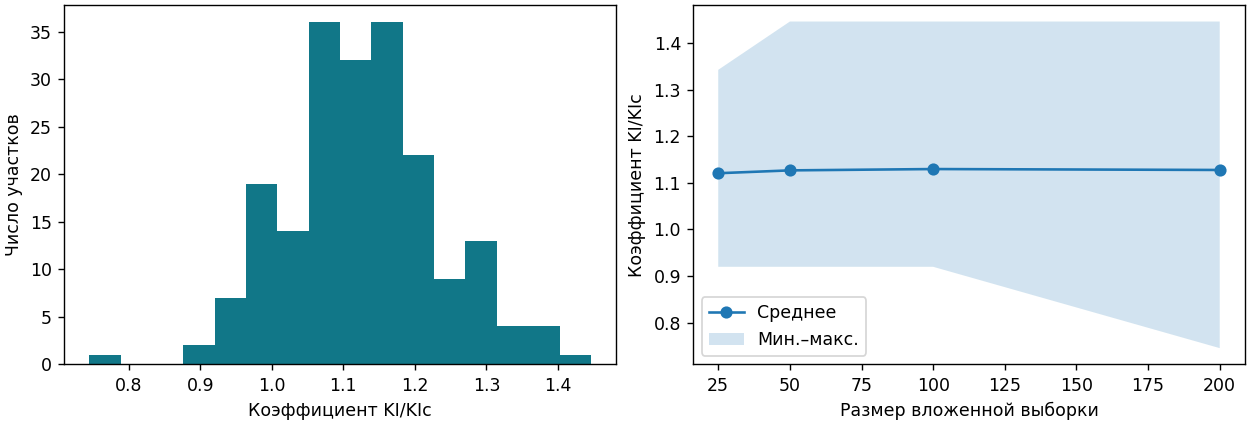

In [5]:
# Одна панель на каждый размер выборки; общая цветовая шкала и одинаковый ракурс.
counts = sorted(set(COUNTS))
fig = plt.figure(figsize=(8,3.4*((len(counts)+1)//2)),layout='constrained')
lo,hi = data.result.min(),data.result.max()
for j,n in enumerate(counts,1):
    ax = fig.add_subplot((len(counts)+1)//2,2,j,projection='3d')
    g = data.iloc[:n]
    t = np.linspace(0,2*np.pi,120)
    for z in [0,H_MM]:
        ax.plot(R_MM*np.cos(t),R_MM*np.sin(t),z,color='gray',lw=.65)
    sc=ax.scatter(g.x_mm,g.y_mm,g.z_mm,c=g.result,cmap='viridis',s=12,
                  vmin=lo,vmax=hi if hi>lo else lo+1e-9)
    ax.set(xlabel='x, мм',ylabel='y, мм',zlabel='z, мм',title=f'N = {n}')
    ax.set_box_aspect((2*R_MM,2*R_MM,H_MM))
fig.colorbar(sc,ax=fig.axes,shrink=.5,label=RESULT_LABEL)
fig.savefig(out/'geometry.png',dpi=125); plt.close(fig)
display(Image(filename=str(out/'geometry.png')))
fig,(a,b) = plt.subplots(1,2,figsize=(10,3.4),layout='constrained')
hist_values = data.result if not np.isclose(lo,hi) else np.full(len(data),float(lo))
a.hist(hist_values,bins='auto',color='#117788')
a.set(xlabel=RESULT_LABEL,ylabel='Число участков')
b.plot(summary.N,summary['mean'],'o-',label='Среднее')
b.fill_between(summary.N.to_numpy(),summary.minimum.to_numpy(),summary.maximum.to_numpy(),alpha=.2,label='Мин.–макс.')
b.set(xlabel='Размер вложенной выборки',ylabel=RESULT_LABEL)
b.legend()
fig.savefig(out/'distribution.png',dpi=125); plt.close(fig)
display(Image(filename=str(out/'distribution.png')))

## 7. Геометрия для CAD

Ноутбук создаёт макрос. Откройте его в FreeCAD через Macro → Macros → Execute из каталога своих CSV. Он запишет по одному STEP на каждый N. Для трещин это помечающие внутренние поверхности: при расчёте разрыва в COMSOL потребуется задать соответствующие условия на гранях. Для включений назначьте материал второй фазы.

In [6]:
(out/'export_geometry.FCMacro').write_text("# Выполняется внешним FreeCAD. Для трещин сохраняются поверхности затравок;\n# для включений — матрица и отдельные тела второй фазы. Файл рядом с CSV.\nimport FreeCAD as App, Part, csv, json\nfrom pathlib import Path\np = Path(__file__).resolve().parent\ncfg = json.loads((p/'parameters.json').read_text(encoding='utf8'))\nfor count in sorted(set(cfg['COUNTS'])):\n    base = Part.makeCylinder(cfg['R_MM'],cfg['H_MM'])\n    shapes=[]\n    with (p/f'sites_N{count}.csv').open(encoding='utf8') as f:\n        for row in csv.DictReader(f):\n            center=App.Vector(*[float(row[k]) for k in ('x_mm','y_mm','z_mm')])\n            a,b,c=[float(row[k])/1000 for k in ('a_um','b_um','c_um')]\n            if cfg['ROLE']=='crack':\n                normal=App.Vector(*[float(row[k]) for k in ('nx','ny','nz')])\n                shape=Part.Face(Part.Wire([Part.makeCircle(a,center,normal)]))\n            elif min(a,b,c)>0:\n                if a==b==c: shape=Part.makeSphere(a,center)\n                else:\n                    m=App.Matrix(); m.A11=a; m.A22=b; m.A33=c\n                    shape=Part.makeSphere(1).transformGeometry(m)\n                    shape.translate(center)\n            else: continue\n            shapes.append(shape)\n    if cfg['ROLE']=='crack':\n        body=Part.Compound([base]+shapes)\n    elif shapes:\n        matrix=base\n        for tool in shapes: matrix=matrix.cut(tool)\n        body=Part.Compound([matrix]+shapes) if cfg['ROLE']=='inclusion' else matrix\n    else: body=base\n    if body.isNull() or not body.isValid(): raise ValueError('Проверка формы FreeCAD не пройдена')\n    body.exportStep(str(p/f'model_N{count}.step'))\n",encoding='utf8')
print(out)

uo2_defect_results/12_shrinkage_crack/run_20261125_225515_359565
